# Detecting Types of Pockets

In this tutorial, we will learn the details on how to how to detect the different tyupes of pockets in am aterial using unsupervised machine learning. For this, we will realy on everything up to the region adjacency graph that we have seen in earlier tutorials. So, if you haven't tried thos out please go back  check those out first, in order to make sense out of this tutorial. You may think of this tutorial as an under-the-hood explanation of the Quick Cluster notebook, among the earlier tutorials. 


The steps needed to detect the different types of pockets are:

- Compute the distance grid
- Region segmentation
- Apply periodic boundary conditions
- Assign cavity level features (purely geometric at this point) to each PBC group.
- Perform clustering (we will be using Agglomerative clustering in this tutorial).
- Visualize the results, to see if it makes sense.

Since, we have already worked up to the region adjacency graph (RAG) so far, we will quickly run through the steps until then without explanation.



## Imports and paths

In [3]:
import sys
import os
# * Put your path here
path_to_mgr = os.path.abspath(
    'c:/Users/arung/OneDrive - The University of Manchester/my_cloned_repos/mofography_general/mofography')
# sys.path.append(path_to_mgr)

import mofography as mgr

path_to_cif = os.path.join(path_to_mgr, 'examples',
                           'TestCIFs', 'P1-IRMOF-1.cif')


## Read the structure

In [4]:
from ase.io import read 
mat_atoms=read(path_to_cif)
mat_updated = mgr.update_with_covalent_bonds(mat_atoms)


c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\ase\io\cif.py:408: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(


## Compute the distance grid

In [5]:
dgrid = mgr.dgrid_from_atoms(mat_atoms, spacing =0.25)

Computing distance grid: 100%|██████████| 23/23 [00:03<00:00,  6.34it/s]


## Region segmentation

In [6]:
regions, maxima = mgr.regions_from_dgrid(dgrid.compute(), mask_thickness=1.5)

c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\mofography-0.0.0-py3.11.egg\mofography\compute.py:904: UserWarning: Some maxima excluded as they fell inside the mask_thickness
  warnings.warn("Some maxima excluded as they fell inside the mask_thickness")


## Applying PBC

In [7]:
maxima_radii = dgrid.compute()[tuple(maxima.T)]
pbc_groups = mgr.apply_pbc(regions, maxima, maxima_radii, mat_atoms, return_conn=True)
regions_pbc = mgr.apply_pbc(regions, maxima, maxima_radii, mat_atoms)

## Region Adjacency Graph

Let's construct a region adjacency graph (RAG) from what we have so far, so that we have a convenient way to hold all the information regarding features and clustering. Just as we've seen in the RAG tutorial,

In [8]:
rag = mgr.get_rag_from_regions_and_grid(regions, dgrid.compute(), mat_atoms, maxima)

In [9]:
rag

*Note:*
It's possible you got an error in this step, it happens with Skimage if no pockets exist (pores are too small) or if none of the regions appear connected because of the currrent mask_thickness. Hence, mofography includes a different function that creates the 
connetions array first (without using Skimage backend) and uses it to create the RAG. This function is much more robust and will be prioritized in the future. 

In [10]:
connections = mgr.connections_from_regions_and_dgrid(regions, dgrid.compute(), maxima, mat_atoms)

which looks the same as in the window detection tutorial. 

In [11]:
connections

array([[array([1, 2]), True, 'internal',
        array([[0.        , 0.        , 7.32734615]]),
        array([3.95200895])],
       [array([1, 3]), False, 'internal', None, None],
       [array([1, 4]), True, 'internal',
        array([[0.        , 7.32734615, 0.        ]]),
        array([3.95200895])],
       ...,
       [array([25, 26]), True, 'internal',
        array([[25.58361538, 25.58361538,  7.32734615]]),
        array([3.67737267])],
       [array([25, 27]), False, 'internal', None, None],
       [array([26, 27]), True, 'internal',
        array([[25.58361538, 25.58361538, 18.25626923]]),
        array([3.68399934])]], dtype=object)

Now we can construct the RAG from the connections list.

In [12]:
rag = mgr.rag_from_connections(connections,maxima)

In [13]:
rag.nodes(data=True), rag.edges(data=True)

(NodeDataView({1: {'labels': [1]}, 2: {'labels': [2]}, 3: {'labels': [3]}, 4: {'labels': [4]}, 5: {'labels': [5]}, 6: {'labels': [6]}, 7: {'labels': [7]}, 8: {'labels': [8]}, 9: {'labels': [9]}, 10: {'labels': [10]}, 11: {'labels': [11]}, 12: {'labels': [12]}, 13: {'labels': [13]}, 14: {'labels': [14]}, 15: {'labels': [15]}, 16: {'labels': [16]}, 17: {'labels': [17]}, 18: {'labels': [18]}, 19: {'labels': [19]}, 20: {'labels': [20]}, 21: {'labels': [21]}, 22: {'labels': [22]}, 23: {'labels': [23]}, 24: {'labels': [24]}, 25: {'labels': [25]}, 26: {'labels': [26]}, 27: {'labels': [27]}}),
 EdgeDataView([(1, 2, {}), (1, 4, {}), (1, 10, {}), (2, 3, {}), (2, 6, {}), (2, 16, {}), (3, 5, {}), (3, 11, {}), (4, 6, {}), (4, 7, {}), (4, 17, {}), (5, 6, {}), (5, 9, {}), (5, 12, {}), (6, 8, {}), (6, 18, {}), (7, 8, {}), (7, 13, {}), (8, 9, {}), (8, 14, {}), (9, 15, {}), (10, 16, {}), (10, 17, {}), (10, 19, {}), (11, 12, {}), (11, 16, {}), (11, 21, {}), (12, 15, {}), (12, 18, {}), (12, 24, {}), (13, 

Let's annotate the RAG with some useful features so that we have everything in one place. Let's add 
- information about PBC
- the centroid of the region including PBC

we will use the region properties that can be easily calcuated by the `regionprops` function in `skimage.measure` for the same

In [14]:
from skimage.measure import regionprops
props = regionprops(regions)


rag = mgr.add_pbc_to_rag(rag, pbc_groups)
rag = mgr.add_centroids_to_rag_with_pbc(rag,props, pbc_groups, mat_atoms, regions.shape)

## Assigning cavity level features

Now we we can annotate each node of the RAG with cavity level features. We can simply use purely geometric, distance based features to represent each pocket. Core set of features built-in to mofography is the pocket size distribution. The pocket size distribution is simply a normalized histogram of the distances of all the points in a region to the centroid of the region. The effect of periodic boundary conditions can be included to the features as follows. For each PBC group (the list of pockets that are connected by periodic boundary conditions), the shortest distance (with PBC) to the periodic centroid is histogrammed. The periodic centroid of a PBC group, is the centroid of a all the points in all the regions in that list, averaged in 3D cyclic coordinates. As a result, the histogram features of given type of cavity that is fully inside a unit cell, and that is split across periodic boundaries will be the same, as long as PBC is accounted for correctly. We can add the pocket size distribution to the RAG as follows after choosing a histogram range that works well in most cases.

In [15]:
import numpy as np
bins = np.linspace(0,30,50)
rag = mgr.add_psd_to_rag_with_pbc(rag, props, pbc_groups, bins, mat_atoms, regions.shape)

## Unsupervised Learning

Let's describe the default choice of algorithms and setting used in unsupervised machine learning on the pockets. Since we do not know how many different types of pockets there are in any material, we choose a heirarchical clustering approach (Agglomerative clustering) that determines the number of clusters automatically.

Let's use the Jensen-Shannon divergence with single linkage as the hyperparameters for the agglomerative clustering. The Jensen-Shannon divergence is a measure of the similarity between two probability distributions. It is defined as the average of the Kullback-Leibler divergences between the probability distributions. It is a symmetric and bounded metric that is always between 0 and 1. It is a good choice for this use case since it is a probabilistic distance which makes it quite robust noise in the samples. Please refer to the Agglomerative clustering in the scikit-learn documentation for more details.

In [16]:
rag=mgr.add_clustering_to_rag_geometry_js(rag, props, pbc_groups, mat_atoms, dgrid.shape)

comp. dist. for clustering: 100%|██████████| 28/28 [00:00<00:00, 128.14it/s]

[0.3627988677975079, 0.3627988677975079, 0.05886725038683047, 0.3627988677975079, 0.05885752225310306, 0.05886725038683047, 0.4142396153462642, 0.0, 0.33383519911697124, 0.0, 0.33384035981620663, 0.33383519911697124, 0.0967087159596938, 0.33383519911697124, 0.0, 0.33384035981620663, 0.33383519911697124, 0.0967087159596938, 0.33383519911697124, 2.2214948333988443e-05, 0.0, 0.389134085035588, 0.33384035981620663, 0.33383519911697124, 0.0967087159596938, 2.2214948333988443e-05, 0.38913832570784995, 0.389134085035588]


after this is called, there should be an data entry to each node under the key 'cluster_geom_pbc' (cluster using geometry with PBC included) that indicates the cluster number that the node belongs to. 

In [17]:
rag.nodes(data=True), rag.edges(data=True)

(NodeDataView({1: {'labels': [1], 'pbc_group': 0, 'centroid_pbc': array([25.70780769, 25.70780769, 25.70780769]), 'psd_x_pbc': array([ 0.30612245,  0.91836735,  1.53061224,  2.14285714,  2.75510204,
         3.36734694,  3.97959184,  4.59183673,  5.20408163,  5.81632653,
         6.42857143,  7.04081633,  7.65306122,  8.26530612,  8.87755102,
         9.48979592, 10.10204082, 10.71428571, 11.32653061, 11.93877551,
        12.55102041, 13.16326531, 13.7755102 , 14.3877551 , 15.        ,
        15.6122449 , 16.2244898 , 16.83673469, 17.44897959, 18.06122449,
        18.67346939, 19.28571429, 19.89795918, 20.51020408, 21.12244898,
        21.73469388, 22.34693878, 22.95918367, 23.57142857, 24.18367347,
        24.79591837, 25.40816327, 26.02040816, 26.63265306, 27.24489796,
        27.85714286, 28.46938776, 29.08163265, 29.69387755]), 'psd_y_pbc': array([0.00096167, 0.00728124, 0.01992037, 0.04107719, 0.06443211,
        0.09671685, 0.14026691, 0.18230577, 0.22901562, 0.29482154,
       

In [18]:
import networkx as nx 
nx.get_node_attributes(rag, 'cluster_geom_pbc')

{1: '0',
 2: '1',
 3: '0',
 4: '1',
 5: '1',
 6: '0',
 7: '0',
 8: '1',
 9: '0',
 10: '1',
 11: '1',
 12: '0',
 13: '1',
 14: '0',
 15: '1',
 16: '0',
 17: '0',
 18: '1',
 19: '0',
 20: '1',
 21: '0',
 22: '1',
 23: '0',
 24: '1',
 25: '0',
 26: '1',
 27: '0'}

note that the node names correspond to the region labels in the segmentation, where the '0' label is the background.

From this example it looks like there are two different types of pockets in this material. Note that clustering here is done with PBC, hence all the pockets in the same PBC group will have the same cluster number.

## Visualizing the results

The best way to visualize the clustering is to color the distance isosurface with the cluster number. We can do this using the `mofography`.
But first we have turn this clustering information into a 3D grid wherer each voxel is labeled wit hthe cluster number. For this we take the 3D grid of regions, find the corresponding PBC group number and map the cluster number on to the PBC group. We can do this using the `mofography` function `clustering_grid_from_regions` as follows.

In [19]:
regions_clusters = mgr.clustering_grid_from_regions(regions, rag, cluster_key='cluster_geom_pbc')

In [20]:
np.unique(regions_clusters)

array([0., 1., 2.])

- 0 background (framework)
- 1 pocket type 1 
- 2 pocket type 2

....

now we are ready to visualize the results. We will show three surfaces in our plot, all on the same 1.75 $\AA$ isosurface. 
- The first layer is the raw region segmentation
- The second layer is after applying PBC
- The third layer is the type of pocket, as determined by the clustering

In [21]:
import plotly.express as px 
import plotly.graph_objects as go
cscale = px.colors.qualitative.Pastel
isosurface_segmentation = mgr.plot_surface_dgrid(dgrid.compute(), stylize=True, isovalue=1.75, region_labels=regions, ase_atoms=mat_atoms, name='isosurface', opacity=1, cscale=cscale)
isosurface_pbc = mgr.plot_surface_dgrid(dgrid.compute(), stylize=True, isovalue=1.75, region_labels=regions_pbc, ase_atoms=mat_atoms, name='pbc',  opacity=1, cscale=cscale )
isosurface_clusters = mgr.plot_surface_dgrid(dgrid.compute(), stylize=True, isovalue=1.75, region_labels=regions_clusters, name='pocket_types', ase_atoms=mat_atoms, opacity=1, cscale=cscale)
cell_trace = mgr.plot_cell(mat_atoms)
frame_trace = mgr.plot_framework_as_mesh(mat_updated, stylize=True)
fig = go.Figure(data=[isosurface_segmentation, isosurface_pbc, isosurface_clusters, cell_trace, *frame_trace])
fig = fig.update(layout=mgr.dark_layout)

c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\pyvista\core\pointset.py:1365: PyVistaDeprecationWarning: The current behavior of `pv.PolyData.n_faces` has been deprecated.
                Use `pv.PolyData.n_cells` or `pv.PolyData.n_faces_strict` instead.
                See the documentation in '`pv.PolyData.n_faces` for more information.
  warnings.warn(


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


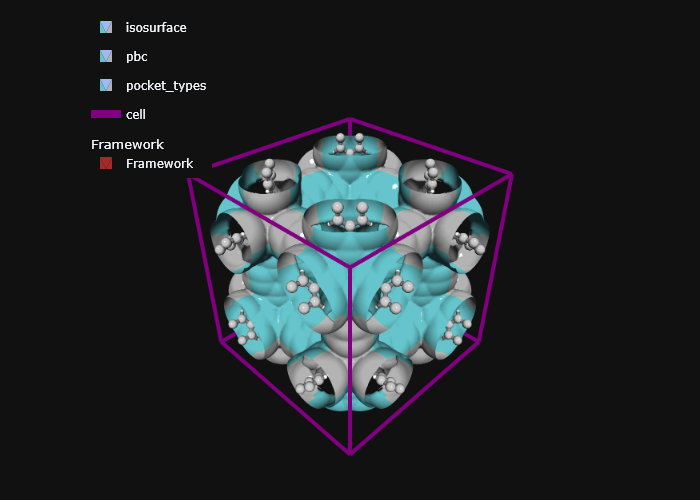

In [22]:
# fig.show(renderer='browser')
fig.show(renderer='png') # change renderer to 'browser' or 'notebook_connected' to interact with the plot

As you can see, the two pocket types are indicated by color. Now, it might seem counterintuitive initially, that there are two types of pockets in IRMOF-1, but this is true. This happens because of the orientation of the aromatic rings on the BDC linkers. We can look at the pocket size distribution of each PBC group to see the difference. We can do this using the `mofography` function `pocket_size_distribution` as follows. Plotting the features is also quite useful for debugging if the clustering seems wrong.


### Plotting the features

Let's plot the pocket size distribution features and color them by the cluster number.

In [23]:
pockets_size_dist_trace = mgr.plot_psds(rag, pbc_groups, cscale=cscale, cluster_key='cluster_geom_pbc')

fig1 = go.Figure(data=[*pockets_size_dist_trace]).update(layout=mgr.dark_layout)
fig1.show(renderer='notebook_connected')

please note the little `*` in front of the pocket_size_dist_trace. This is because the function returns a list, and we need to unpack it to add to the Plolty figure.


As you can see there are two disntinct type of pockets, detected by mofography in IRMOF-1

### Adjusting the threshold

In the clustering function there is an option to adjust the Jensen SHannon distance threshold, by default it is set to 0.15, meaning if the pockets are more than 15% different, then they are considered different. You may change that for your use case, for example, in the case of IRMOF-1 if we increase that value substantially, you'll see only one type of pocket detected.

comp. dist. for clustering: 100%|██████████| 28/28 [00:00<00:00, 133.01it/s]


[0.3627988677975079, 0.3627988677975079, 0.05886725038683047, 0.3627988677975079, 0.05885752225310306, 0.05886725038683047, 0.4142396153462642, 0.0, 0.33383519911697124, 0.0, 0.33384035981620663, 0.33383519911697124, 0.0967087159596938, 0.33383519911697124, 0.0, 0.33384035981620663, 0.33383519911697124, 0.0967087159596938, 0.33383519911697124, 2.2214948333988443e-05, 0.0, 0.389134085035588, 0.33384035981620663, 0.33383519911697124, 0.0967087159596938, 2.2214948333988443e-05, 0.38913832570784995, 0.389134085035588]
Unique clusters: [0. 1.]
No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


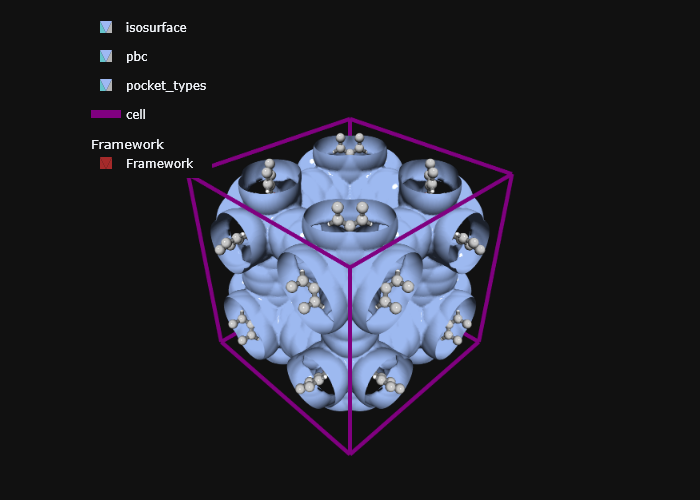

In [24]:
rag = mgr.add_clustering_to_rag_geometry_js(rag, props, pbc_groups, mat_atoms, dgrid.shape, js_threshold=0.5) # 50% is way too high, but just for the sake of the example

regions_clusters = mgr.clustering_grid_from_regions(regions, rag, cluster_key='cluster_geom_pbc')
print('Unique clusters:', np.unique(regions_clusters))
import plotly.express as px 
import plotly.graph_objects as go
cscale = px.colors.qualitative.Pastel
isosurface_segmentation = mgr.plot_surface_dgrid(dgrid.compute(), stylize=True, isovalue=1.75, region_labels=regions, ase_atoms=mat_atoms, name='isosurface', opacity=1, cscale=cscale)
isosurface_pbc = mgr.plot_surface_dgrid(dgrid.compute(), stylize=True, isovalue=1.75, region_labels=regions_pbc, ase_atoms=mat_atoms, name='pbc',  opacity=1, cscale=cscale )
isosurface_clusters = mgr.plot_surface_dgrid(dgrid.compute(), stylize=True, isovalue=1.75, region_labels=regions_clusters, name='pocket_types', ase_atoms=mat_atoms, opacity=1, cscale=cscale)
cell_trace = mgr.plot_cell(mat_atoms)
frame_trace = mgr.plot_framework_as_mesh(mat_updated, stylize=True)
fig = go.Figure(data=[isosurface_segmentation, isosurface_pbc, isosurface_clusters, cell_trace, *frame_trace])
fig = fig.update(layout=mgr.dark_layout)

fig.show(renderer='png')

## Pockets detection using energy

As mentioned earlier, one great flexibility of graphs is that we can use whatever features we want to describe each node. In mofography, there is also an option to detect pocket types using simple VdW energy calculations using UFF force field and  helium probe, instead of geometric features. Sometimes this can be more useful, especially if you are already calculating the energy grid for something else. Also, the natural shape of Lennard-Jones potential makes it more sensitive close to the framework and less sensitive far away, which is good for describing pocket shape.

In [25]:
rag = mgr.add_clustering_to_rag_energy_js(rag, regions, energy_interpolator=None, js_threshold=0.15, ase_atoms=mat_atoms, pbc_groups = pbc_groups) # energy histograms are way more sensitive. 5% is good default choice

If you want, you can compute the energy grid first, make an interpolator and then pass that along to speed up the process substantially (otherwise it will compute the energy at a bunch of sampled points for each region). We can do another tutorial on energy grid calculation, force fields and probes, if there is interest.

In [26]:
egrid = mgr.egrid_from_atoms2(mat_atoms, spacing=0.5, probe_symbol='He').compute()
einterpolator = mgr.interpolate_dgrid(egrid) # we can use the same interpolator as that for the distance grid, because at the end of the day, it's just a 3D array and we are interpolating in fractional coordinates

rag = mgr.add_clustering_to_rag_energy_js(rag, regions, energy_interpolator=einterpolator, js_threshold=0.15, pbc_groups = pbc_groups) # no need for ase_atoms, because we already have the energy interpolator 

#### Visualize the results
Let's visualize the results and plot the energy histogram features.

Unique clusters: [0. 1. 2.]
No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


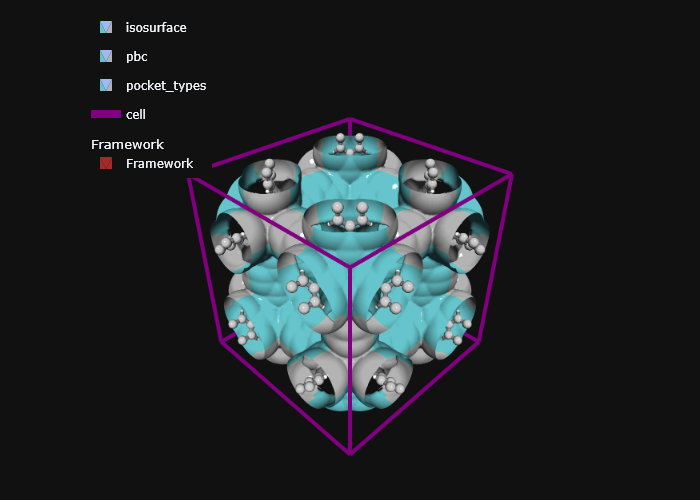

In [27]:

regions_clusters = mgr.clustering_grid_from_regions(regions, rag, cluster_key='cluster_energy_pbc')
print('Unique clusters:', np.unique(regions_clusters))
import plotly.express as px 
import plotly.graph_objects as go
cscale = px.colors.qualitative.Pastel
isosurface_segmentation = mgr.plot_surface_dgrid(dgrid.compute(), stylize=True, isovalue=1.75, region_labels=regions, ase_atoms=mat_atoms, name='isosurface', opacity=1, cscale=cscale)
isosurface_pbc = mgr.plot_surface_dgrid(dgrid.compute(), stylize=True, isovalue=1.75, region_labels=regions_pbc, ase_atoms=mat_atoms, name='pbc',  opacity=1, cscale=cscale )
isosurface_clusters = mgr.plot_surface_dgrid(dgrid.compute(), stylize=True, isovalue=1.75, region_labels=regions_clusters, name='pocket_types', ase_atoms=mat_atoms, opacity=1, cscale=cscale)
cell_trace = mgr.plot_cell(mat_atoms)
frame_trace = mgr.plot_framework_as_mesh(mat_updated, stylize=True)
fig = go.Figure(data=[isosurface_segmentation, isosurface_pbc, isosurface_clusters, cell_trace, *frame_trace])
fig = fig.update(layout=mgr.dark_layout)

fig.show(renderer='png')

#### *Note:*

There is something you need to know about JS metric. 
The inputs to the metric are the actual sampled energy values (lists) from each of the distributions that we want to compare, and not the histograms themselves, hence in order to plot as histograms, we need to histogram the energy values first. 

#### Plot the energy histogram features

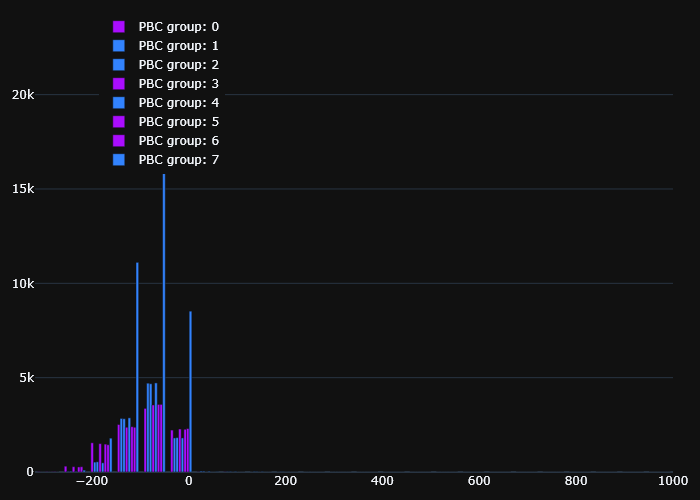

In [28]:
rag = mgr.add_vdw_hist_to_rag(rag, regions, use_pbc=True, pbc_groups=pbc_groups, energy_interpolator=einterpolator)
energy_hists_traces = mgr.plot_vdw_hists(rag, pbc_groups, cluster_key='cluster_energy_pbc')


fig2 = go.Figure(data=[*energy_hists_traces]).update(layout=mgr.dark_layout)
fig2.show(renderer='png')

The energy histograms here are fairly similar, since they only differ by the orientation of the BDC linker, hence, that makes sense.
Please see the function docstrings for more details on the parameters.

## Where to next?

We are almost at the end of the Basic Tutorials. One thing that we can do with the knowledge of the pockets is to detect the different types of channels present in the material. What we consider as a channel and how we can use some ideas from Graph theory to detect and distinguish them in practice is in the Detecting Paths tutorial. 

Also, with your current mastery of the Basic Tutorials, all of the Advanced Tutorials should be quite accessible to you. So, feel free to jump there as well.